In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


# **Download Visual Transformers**

In [1]:
!pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-_rtn52kh
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-_rtn52kh
  Resolved https://github.com/openai/CLIP.git to commit a1d071733d7111c9c014f024669f959182114e33
  Preparing metadata (setup.py) ... done


In [2]:
!pip install timm

# **Import Libraries**

In [3]:
import torch
import clip
import timm
from PIL import Image
import os
import torchvision
import tarfile
from torchvision.datasets.utils import download_url
from torch.utils.data import random_split
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor
from torchvision import models
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as tt
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from torchvision.utils import make_grid
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import torchvision.transforms as T
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
%matplotlib inline
matplotlib.rcParams['figure.facecolor'] = '#ffffff'

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [5]:
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

# **Ready VTs**

In [6]:
clip_model, preprocess = clip.load("ViT-B/32", device=device)
clip_model = clip_model.visual

In [7]:
torch_vision_model = torch.hub.load("pytorch/vision", "resnet50", weights="IMAGENET1K_V2")
torch_vision_model = torch.nn.Sequential(*list(torch_vision_model.children())[:-1])

Using cache found in /root/.cache/torch/hub/pytorch_vision_main


In [8]:
timm_inception_model = timm.create_model('resnet50', pretrained=True, num_classes=0)

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:72: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


# **Ready Dataset**

In [9]:
!gdown 1BRccmUBnxhbthHL0bxVz1nLD7OSbZ3r2
!unzip train.zip
!rm train.zip
!rm -r ./train/1
!rm -r ./train/2
!rm -r ./train/4
!rm -r ./train/6

Streaming output truncated to the last 5000 lines.
  inflating: train/6/s6_39679_s6_40_105.png  
  inflating: train/6/s6_39684_s6_40_105.png  
  inflating: train/6/s6_39688_s6_40_105.png  
  inflating: train/6/s6_39690_s6_40_105.png  
  inflating: train/6/s6_39694_s6_40_105.png  
  inflating: train/6/s6_39699_s6_40_105.png  
  inflating: train/6/s6_39709_s6_40_105.png  
  inflating: train/6/s6_39711_s6_40_105.png  
  inflating: train/6/s6_39718_s6_40_105.png  
  inflating: train/6/s6_39729_s6_40_105.png  
  inflating: train/6/s6_39733_s6_40_105.png  
  inflating: train/6/s6_39748_s6_40_144.png  
  inflating: train/6/s6_39749_s6_40_144.png  
  inflating: train/6/s6_39761_s6_40_144.png  
  inflating: train/6/s6_39768_s6_40_144.png  
  inflating: train/6/s6_39770_s6_40_144.png  
  inflating: train/6/s6_39776_s6_40_144.png  
  inflating: train/6/s6_39782_s6_40_144.png  
  inflating: train/6/s6_39783_s6_40_144.png  
  inflating: train/6/s6_39787_s6_40_144.png  
  inflating: train/6/s6_39790

In [10]:
!gdown 13mgPPoiktXLovSHvV13vmz-1W6F6EwJq
!unzip bracs_in_test.zip
!rm bracs_in_test.zip
!rm -r ./test/1
!rm -r ./test/2
!rm -r ./test/4
!rm -r ./test/6

Streaming output truncated to the last 5000 lines.
  inflating: test/2/s2_10031_s2_8_14.png  
  inflating: test/2/s2_10038_s2_8_150.png  
  inflating: test/2/s2_10041_s2_8_150.png  
  inflating: test/2/s2_10046_s2_8_150.png  
  inflating: test/2/s2_10048_s2_8_150.png  
  inflating: test/2/s2_10050_s2_8_150.png  
  inflating: test/2/s2_10053_s2_8_150.png  
  inflating: test/2/s2_10063_s2_8_44.png  
  inflating: test/2/s2_10065_s2_8_44.png  
  inflating: test/2/s2_10082_s2_8_49.png  
  inflating: test/2/s2_10085_s2_8_49.png  
  inflating: test/2/s2_1008_s2_0_92.png  
  inflating: test/2/s2_10103_s2_9_107.png  
  inflating: test/2/s2_10114_s2_9_122.png  
  inflating: test/2/s2_1011_s2_0_92.png  
  inflating: test/2/s2_10134_s2_9_122.png  
  inflating: test/2/s2_10136_s2_9_14.png  
  inflating: test/2/s2_10165_s2_9_150.png  
  inflating: test/2/s2_10166_s2_9_150.png  
  inflating: test/2/s2_10187_s2_9_150.png  
  inflating: test/2/s2_1018_s2_0_92.png  
  inflating: test/2/s2_10191_s2_9_150

In [9]:
data_dir = '.'
dataset = ImageFolder(data_dir+'/train', transform=ToTensor())
random_seed = 42
torch.manual_seed(random_seed)
val_size = int(len(dataset) * 0.1)
train_size = len(dataset) - val_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])
len(train_ds), len(val_ds)

(26759, 2973)

In [10]:
train_dict = {}

for i, (image, label) in enumerate(train_ds):
  if not label in train_dict.keys():
    train_dict[label] = []
  train_dict[label].append(i)

In [11]:
valid_dict = {}

for i, (image, label) in enumerate(val_ds):
  if not label in valid_dict.keys():
    valid_dict[label] = []
  valid_dict[label].append(i)

In [12]:
class CustomDataset(Dataset):
    def __init__(self, ds, main_dict):
        self.ds = ds
        self.main_dict = main_dict

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        image, label = self.ds[idx][0], self.ds[idx][1]

        chosen_positive_sample = random.choice(self.main_dict[label])
        positive_image, positive_label = self.ds[chosen_positive_sample][0], self.ds[chosen_positive_sample][1]

        all_negative_samples = []
        for key in self.main_dict.keys():
          if key != label:
            all_negative_samples += self.main_dict[key]
        chosen_negative_sample = random.choice(all_negative_samples)
        negative_image, negative_label = self.ds[chosen_negative_sample][0], self.ds[chosen_negative_sample][1]

        return image, label, positive_image, positive_label, negative_image, negative_label

In [13]:
train_ds = CustomDataset(train_ds, train_dict)
val_ds = CustomDataset(val_ds, valid_dict)

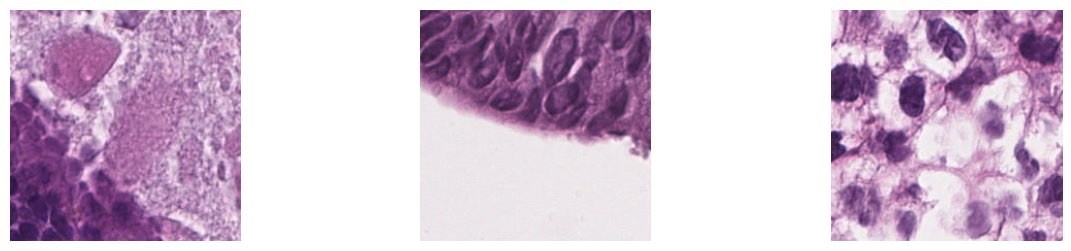

In [14]:
counter = 0
for image, label, positive_image, positive_label, negative_image, negative_label in train_ds:
  if counter == 20:
    image_tensor = np.transpose(image, (1, 2, 0))
    positive_image_tensor = np.transpose(positive_image, (1, 2, 0))
    negative_image_tensor = np.transpose(negative_image, (1, 2, 0))

    fig, axs = plt.subplots(1, 3, figsize=(15, 3))

    axs[0].imshow(image_tensor)
    axs[0].axis("off")
    axs[1].imshow(positive_image_tensor)
    axs[1].axis("off")
    axs[2].imshow(negative_image_tensor)
    axs[2].axis("off")

    plt.show()

    break

  counter += 1

In [15]:
batch_size = 16
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=batch_size * 2)

# **Model Codes**

In [16]:
class ImageClassificationBase(nn.Module):
    def training_step(self, loss_func, images, positive_images, negative_images):
        embeddings = self(images)
        positive_embeddings = self(positive_images)
        negative_embeddings = self(negative_images)
        loss = loss_func(embeddings, positive_embeddings, negative_embeddings)
        return loss

    def validation_step(self, loss_func, images, positive_images, negative_images):
        embeddings = self(images)
        positive_embeddings = self(positive_images)
        negative_embeddings = self(negative_images)
        loss = loss_func(embeddings, positive_embeddings, negative_embeddings)
        return {'val_loss': loss.detach()}

    def validation_epoch_end(self, outputs):
        batch_losses = [x['val_loss'] for x in outputs]
        epoch_loss = torch.stack(batch_losses).mean()
        return {'val_loss': epoch_loss.item()}

    def epoch_end(self, epoch, result):
        print("Epoch [{}], train_loss: {:.4f}, val_loss: {:.4f}".format(
            epoch, result['train_loss'], result['val_loss']))

In [17]:
def get_default_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    else:
        return torch.device('cpu')

def to_device(data, device):
    if isinstance(data, (list,tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)

class DeviceDataLoader():
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device

    def __iter__(self):
        for b in self.dl:
            yield to_device(b, self.device)

    def __len__(self):
        return len(self.dl)

In [18]:
device = get_default_device()
device

device(type='cuda')

In [19]:
class Cifar10CnnModel(ImageClassificationBase):
    def __init__(self, vt):
        super().__init__()
        if vt == "clip":
          self.vt = clip_model
          self.embedding = nn.Sequential(
              nn.Linear(512, 256),
              nn.ReLU()
          )
        if vt == "torch vision":
          self.vt = torch_vision_model
          self.embedding = nn.Sequential(
              nn.Flatten(),
              nn.Linear(2048, 256),
              nn.ReLU()
          )
        if vt == "timm inception":
          self.vt = timm_inception_model
          self.embedding = nn.Sequential(
              nn.Linear(2048, 256),
              nn.ReLU()
          )

    def forward(self, xb):
        xb = self.vt(xb)
        embedding = self.embedding(xb)
        return embedding

In [20]:
@torch.no_grad()
def evaluate(model, val_loader, loss_func):
    model.eval()
    outputs = list()
    for images, labels, positive_images, positive_labels, negative_images, negative_labels in tqdm(val_loader):
      outputs.append(model.validation_step(loss_func, images, positive_images, negative_images))
    return model.validation_epoch_end(outputs)

In [21]:
def fit(start_epoch, epochs, lr, model, train_loader, val_loader, loss_func, optimizer):
    history = []

    for epoch in range(start_epoch, epochs):
        model.train()
        train_losses = []
        for images, labels, positive_images, positive_labels, negative_images, negative_labels in tqdm(train_loader):
            loss = model.training_step(loss_func, images, positive_images, negative_images)

            train_losses.append(loss)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        result = evaluate(model, val_loader, loss_func)
        result['train_loss'] = torch.stack(train_losses).mean().item()
        model.epoch_end(epoch, result)
        history.append(result)

        if epoch % 2 == 0:
          save_dict = {
              'model': model.state_dict(),
              'optimizer': optimizer.state_dict(),
              'loss': loss_func.state_dict(),
              'epoch': epoch + 1
          }
          torch.save(save_dict, f"./gdrive/MyDrive/ModularRetrieval/end_of_epoch{epoch+1}.pth")

    return history

In [22]:
model = Cifar10CnnModel("timm inception")
train_dl = DeviceDataLoader(train_dl, device)
val_dl = DeviceDataLoader(val_dl, device)
to_device(model, device)

Cifar10CnnModel(
  (vt): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act1): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (drop_block): Identity()
        (act2): ReLU(inplace=True)
        (aa): Identity()
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, m

In [23]:
num_epochs = 10
lr = 0.0001
opt_func = torch.optim.Adam
optimizer = opt_func(model.parameters(), lr)
loss_func = nn.TripletMarginLoss(margin=1.0, p=2, eps=1e-7)

<font color="yellow">
if you have a checkpoint, give the address in below cell
</font>

In [27]:
# this is checkpoint at the end of epoch 9
!gdown -O ./checkpoint.pth 1-E3ktYvBbkzfvwozDH4MUFtR5W-Juiv0

Downloading...
From: https://drive.google.com/uc?id=1-E3ktYvBbkzfvwozDH4MUFtR5W-Juiv0
To: /content/checkpoint.pth
100% 289M/289M [00:03<00:00, 86.1MB/s]


In [25]:
CHECKPOINT_PATH = "./checkpoint.pth"

start_epoch = 0
if os.path.isfile(CHECKPOINT_PATH):
  checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")
  model.load_state_dict(checkpoint['model'], strict=False)
  model.to(device)
  optimizer.load_state_dict(checkpoint['optimizer'])
  loss_func.load_state_dict(checkpoint['loss'], strict=False)
  loss_func.to(device)
  start_epoch = int(checkpoint['epoch'])

In [26]:
if torch.cuda.is_available():
  model = model.type(torch.cuda.FloatTensor)
history = fit(start_epoch, num_epochs, lr, model, train_dl, val_dl, loss_func, optimizer)

100%|██████████| 93/93 [01:07<00:00,  1.38it/s]


Epoch [9], train_loss: 0.1192, val_loss: 0.3499


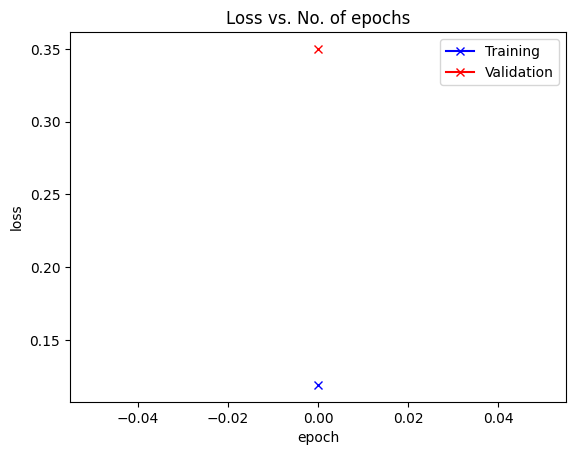

In [27]:
def plot_losses(history):
    train_losses = [x.get('train_loss') for x in history]
    val_losses = [x['val_loss'] for x in history]
    plt.plot(train_losses, '-bx')
    plt.plot(val_losses, '-rx')
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(['Training', 'Validation'])
    plt.title('Loss vs. No. of epochs')

plot_losses(history)